<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h1 style="color:#0F2A4A">نوت‌بوک ۳ — طبقه‌بندی بیزی ساده‌لوح</h1>
<h2 style="color:#0E7490">Naive Bayes Classifier</h2>
<p>طبقه‌بند احتمالاتی مبتنی بر <b>قضیه بیز</b> با فرض استقلال ویژگی‌ها: <code>P(C|X) ∝ P(C) × Π P(xi|C)</code> — «ساده‌لوح» چون همین فرض ساده‌کننده را دارد.</p>
<p>در این نوت‌بوک:</p>
<ul><li>محاسبه دستی احتمال‌ها روی مثال تنیس</li><li>GaussianNB روی داده پیوسته Iris + ماتریس درهم‌ریختگی</li></ul>
<p style="color:#45607A; font-size:13px">همراه ارائه درس «داده‌کاوی و یادگیری ماشین» — برای اجرا در Google Colab: هر سلول را با <b>Shift+Enter</b> اجرا کنید و پارامترها را آزادانه تغییر دهید.</p>
<hr style="border:0;border-top:1px dashed #B7DFEA;margin:10px 0">
<p style="background:#EBF7FA;border:1px solid #B7DFEA;border-radius:8px;padding:10px 12px">
🛠 <b>راهنمای استفاده:</b> همهٔ کدها در <b>Google Colab</b> اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: <b>Shift+Enter</b> یا منوی Runtime ▸ Run all).<br>
🐍 <b>یادگیری پایتون، از صفر:</b> <a href="https://www.w3schools.com/python/default.asp">W3Schools — Python Tutorial</a> — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.<br>
📝 <b>هر سلول:</b> توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.
</p>
</div>

In [1]:
# تنظیمات اولیه: واردکردن کتابخانه‌ها + پالت رنگی و ظاهر یکسان نمودارها
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TEAL, NAVY, AMBER = "#0E7490", "#0F2A4A", "#B45309"
plt.rcParams.update({"figure.facecolor":"white","axes.grid":True,"grid.color":"#D8E2EC",
    "axes.edgecolor":"#94A3B8","axes.labelcolor":"#0F2A4A","text.color":"#0F2A4A",
    "axes.titlecolor":"#0F2A4A","axes.titleweight":"bold","legend.frameon":False,
    "xtick.color":"#334155","ytick.color":"#334155"})
print("libraries ready")

libraries ready


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۱) محاسبه دستی روی تنیس</h2>
<p>روز جدید: آسمان = آفتابی، رطوبت = بالا، باد = قوی. فقط با شمارش فراوانی‌ها:</p>
</div>

In [2]:
# محاسبهٔ دستی Bayes برای روزِ {آفتابی، رطوبت بالا، باد تند} — همان اعداد اسلاید
tennis = pd.DataFrame({
    "Outlook":  ["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast",
                 "Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
    "Humidity": ["High","High","High","High","Normal","Normal","Normal",
                 "High","Normal","Normal","Normal","High","Normal","High"],
    "Wind":     ["Weak","Strong","Weak","Weak","Weak","Strong","Strong",
                 "Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
    "Play":     ["No","No","Yes","Yes","Yes","No","Yes",
                 "No","Yes","Yes","Yes","Yes","Yes","No"]})

day = {"Outlook": "Sunny", "Humidity": "High", "Wind": "Strong"}
P_yes = (tennis.Play=="Yes").mean();  P_no = (tennis.Play=="No").mean()
lik_yes = np.prod([(tennis.loc[tennis.Play=="Yes", f]==v).mean() for f,v in day.items()])
lik_no  = np.prod([(tennis.loc[tennis.Play=="No",  f]==v).mean() for f,v in day.items()])
print(f"P(Yes) x likelihood = {P_yes:.3f} x {lik_yes:.3f} = {P_yes*lik_yes:.4f}")
print(f"P(No)  x likelihood = {P_no:.3f} x {lik_no:.3f} = {P_no*lik_no:.4f}")
print(f"posterior P(Yes|day) = {P_yes*lik_yes/(P_yes*lik_yes+P_no*lik_no):.1%}")
print(f"posterior P(No |day) = {P_no*lik_no /(P_yes*lik_yes+P_no*lik_no):.1%}")

P(Yes) x likelihood = 0.643 x 0.025 = 0.0159
P(No)  x likelihood = 0.357 x 0.288 = 0.1029
posterior P(Yes|day) = 13.4%
posterior P(No |day) = 86.6%


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۲) GaussianNB روی Iris</h2>
<p>برای ویژگی‌های <b>پیوسته</b> از توزیع نرمال استفاده می‌شود.</p>
</div>

In [3]:
# GaussianNB روی Iris: آموزش، پیش‌بینی و گزارش کامل طبقه‌بندی
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.15,
                                          random_state=42, stratify=y)
nb = GaussianNB().fit(X_tr, y_tr)
y_pred = nb.predict(X_te)
print("Test accuracy:", nb.score(X_te, y_te))
print(classification_report(y_te, y_pred, target_names=load_iris().target_names))

Test accuracy: 0.9130434782608695
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       0.88      0.88      0.88         8
   virginica       0.88      0.88      0.88         8

    accuracy                           0.91        23
   macro avg       0.92      0.92      0.92        23
weighted avg       0.91      0.91      0.91        23



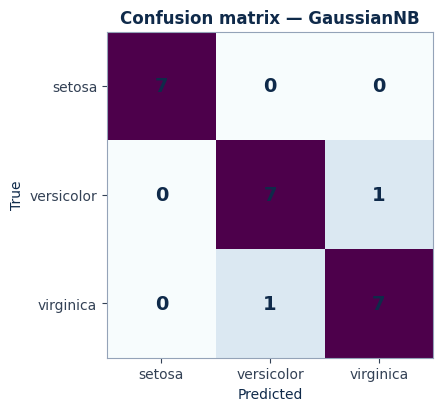

In [4]:
# ماتریس اغتشاش GaussianNB — خانه‌های غیرقطری، خطاهای مدل‌اند
cm = confusion_matrix(y_te, y_pred)
fig, ax = plt.subplots(figsize=(5,4), layout="constrained")
im = ax.imshow(cm, cmap="BuPu")
ax.set_xticks(range(3), load_iris().target_names)
ax.set_yticks(range(3), load_iris().target_names)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i,j], ha="center", va="center", fontsize=14, fontweight="bold")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.grid(False)
ax.set_title("Confusion matrix — GaussianNB")
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">جمع‌بندی</h2>
<ul><li>بیز ساده‌لوح فقط شمارش و ضرب احتمال است — بسیار سریع</li><li>با داده کم هم خوب کار می‌کند؛ پایه فیلترهای اسپم</li><li>خطاها معمولاً جایی است که کلاس‌ها هم‌پوشانی دارند (versicolor/virginica)</li></ul>
<p style="color:#45607A">قدم بعدی: پارامترها (مثل k یا max_depth) را تغییر دهید و اثرشان را روی خروجی ببینید.</p>
</div>